In [2]:
import pandas as pd  
import matplotlib.pyplot as plt 
import seaborn as sns


In [3]:
df = pd.read_csv(r"C:\Users\gaura\Downloads\Balaji_Fast_Food_Sales.csv")

In [4]:
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
0,1,07-03-2022,Aalopuri,Fastfood,20,13,260,NaN,Mr.,Night
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening
...,...,...,...,...,...,...,...,...,...,...
995,996,3/19/2023,Frankie,Fastfood,50,10,500,NaN,Mrs.,Evening
996,997,9/20/2022,Sandwich,Fastfood,60,7,420,NaN,Mr.,Evening
997,998,1/26/2023,Sandwich,Fastfood,60,13,780,NaN,Mr.,Evening
998,999,8/27/2022,Panipuri,Fastfood,20,5,100,NaN,Mrs.,Afternoon


In [5]:
print(df.shape)

(1000, 10)


In [6]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            1000 non-null   int64
 1   date                1000 non-null   str  
 2   item_name           1000 non-null   str  
 3   item_type           1000 non-null   str  
 4   item_price          1000 non-null   int64
 5   quantity            1000 non-null   int64
 6   transaction_amount  1000 non-null   int64
 7   transaction_type    893 non-null    str  
 8   received_by         1000 non-null   str  
 9   time_of_sale        1000 non-null   str  
dtypes: int64(4), str(6)
memory usage: 78.3 KB
None


In [7]:
print(df.describe())

          order_id   item_price     quantity  transaction_amount
count  1000.000000  1000.000000  1000.000000         1000.000000
mean    500.500000    33.315000     8.162000          275.230000
std     288.819436    14.921744     4.413075          204.402979
min       1.000000    20.000000     1.000000           20.000000
25%     250.750000    20.000000     4.000000          120.000000
50%     500.500000    25.000000     8.000000          240.000000
75%     750.250000    50.000000    12.000000          360.000000
max    1000.000000    60.000000    15.000000          900.000000


In [8]:
print(df.isnull().sum()) ## missing values find karnyasathi

order_id                0
date                    0
item_name               0
item_type               0
item_price              0
quantity                0
transaction_amount      0
transaction_type      107
received_by             0
time_of_sale            0
dtype: int64


In [9]:
miss_percentage=(df.isnull().sum()/len(df))*100
print(miss_percentage)

order_id               0.0
date                   0.0
item_name              0.0
item_type              0.0
item_price             0.0
quantity               0.0
transaction_amount     0.0
transaction_type      10.7
received_by            0.0
time_of_sale           0.0
dtype: float64


In [10]:
df["transaction_type"]=df["transaction_type"].fillna("Unknown") ## transaction id madlya null values la apn unknown name del ani khali null values count bagitl
print(df["transaction_type"].isnull().sum())

0


In [11]:
print("duplicate",df.duplicated().sum())

duplicate 0


In [12]:
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
0,1,07-03-2022,Aalopuri,Fastfood,20,13,260,Unknown,Mr.,Night
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening
...,...,...,...,...,...,...,...,...,...,...
995,996,3/19/2023,Frankie,Fastfood,50,10,500,Unknown,Mrs.,Evening
996,997,9/20/2022,Sandwich,Fastfood,60,7,420,Unknown,Mr.,Evening
997,998,1/26/2023,Sandwich,Fastfood,60,13,780,Unknown,Mr.,Evening
998,999,8/27/2022,Panipuri,Fastfood,20,5,100,Unknown,Mrs.,Afternoon


In [13]:
df["date"]=pd.to_datetime (df["date"], dayfirst=True,errors="coerce")
print(df["date"].head())
print(df["date"].min())
print(df["date"].max())

0   2022-03-07
1          NaT
2          NaT
3   2023-03-02
4   2022-02-10
Name: date, dtype: datetime64[us]
2022-01-04 00:00:00
2023-12-03 00:00:00


In [14]:
print("Rows and Columns:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

Rows and Columns: (1000, 10)

Missing Values:
order_id                0
date                  597
item_name               0
item_type               0
item_price              0
quantity                0
transaction_amount      0
transaction_type        0
received_by             0
time_of_sale            0
dtype: int64


In [17]:
items = df[["item_name", "item_type", "item_price"]]

items = items.drop_duplicates()

print(items.sort_values("item_name"))

          item_name  item_type  item_price
0          Aalopuri   Fastfood          20
19      Cold coffee  Beverages          40
10          Frankie   Fastfood          50
7          Panipuri   Fastfood          20
15         Sandwich   Fastfood          60
3   Sugarcane juice  Beverages          25
1           Vadapav   Fastfood          20


In [18]:
total_revenue = df["transaction_amount"].sum()

total_units = df["quantity"].sum()

average_order_value = df["transaction_amount"].mean()

print("Total Revenue:", total_revenue)

print("Total Units Sold:", total_units)

print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 275230
Total Units Sold: 8162
Average Order Value: 275.23


In [19]:
item_orders = (
    df.groupby("item_name")["order_id"]
    .count()
    .sort_values(ascending=False)
)

print(item_orders)

item_name
Cold coffee        161
Sugarcane juice    153
Panipuri           150
Frankie            139
Aalopuri           134
Vadapav            134
Sandwich           129
Name: order_id, dtype: int64


In [20]:
print("Most Orders:")
print(item_orders.idxmax(), item_orders.max())

Most Orders:
Cold coffee 161


In [21]:
print("Fewest Orders:")
print(item_orders.idxmin(), item_orders.min())

Fewest Orders:
Sandwich 129


In [22]:
item_analysis = df.groupby("item_name").agg(
    total_orders=("order_id", "count"),
    total_revenue=("transaction_amount", "sum")
)

item_analysis = item_analysis.sort_values(
    "total_revenue",
    ascending=False
)

print(item_analysis)

                 total_orders  total_revenue
item_name                                   
Sandwich                  129          65820
Frankie                   139          57500
Cold coffee               161          54440
Sugarcane juice           153          31950
Panipuri                  150          24520
Aalopuri                  134          20880
Vadapav                   134          20120


In [23]:
df["date"] = pd.to_datetime(
    df["date"],
    format="mixed",
    dayfirst=False,
    errors="coerce"
)

print("Earliest Date:", df["date"].min())

print("Latest Date:", df["date"].max())

Earliest Date: 2022-01-04 00:00:00
Latest Date: 2023-12-03 00:00:00


In [24]:
print(df["transaction_type"].value_counts())

transaction_type
Cash       476
Online     417
Unknown    107
Name: count, dtype: int64


In [25]:
unknown_count = (df["transaction_type"] == "Unknown").sum()

unknown_percentage = (unknown_count / len(df)) * 100

print("Unknown Orders:", unknown_count)

print("Unknown Percentage:", round(unknown_percentage, 2), "%")

Unknown Orders: 107
Unknown Percentage: 10.7 %


In [26]:
df["calculated_amount"] = (
    df["item_price"] * df["quantity"]
)

df["amount_matches"] = (
    df["transaction_amount"] == df["calculated_amount"]
)

print(df["amount_matches"].value_counts())

amount_matches
True    1000
Name: count, dtype: int64


In [27]:
incorrect_rows = df[df["amount_matches"] == False]

print(incorrect_rows)

Empty DataFrame
Columns: [order_id, date, item_name, item_type, item_price, quantity, transaction_amount, transaction_type, received_by, time_of_sale, calculated_amount, amount_matches]
Index: []


In [28]:
df["month"] = df["date"].dt.month_name()

df["weekday"] = df["date"].dt.day_name()

df["is_weekend"] = df["date"].dt.dayofweek >= 5

In [29]:
df[["date", "month", "weekday", "is_weekend"]].head(10)

,date,month,weekday,is_weekend
0,2022-03-07,March,Monday,False
1,NaT,NaN,NaN,False
2,NaT,NaN,NaN,False
3,2023-03-02,March,Thursday,False
4,2022-02-10,February,Thursday,False
5,NaT,NaN,NaN,False
6,2022-03-05,March,Saturday,True
7,NaT,NaN,NaN,False
8,2022-10-06,October,Thursday,False
9,NaT,NaN,NaN,False


In [30]:
item_revenue = (
    df.groupby("item_name")["transaction_amount"]
    .sum()
    .sort_values(ascending=False)
)

print(item_revenue)

item_name
Sandwich           65820
Frankie            57500
Cold coffee        54440
Sugarcane juice    31950
Panipuri           24520
Aalopuri           20880
Vadapav            20120
Name: transaction_amount, dtype: int64


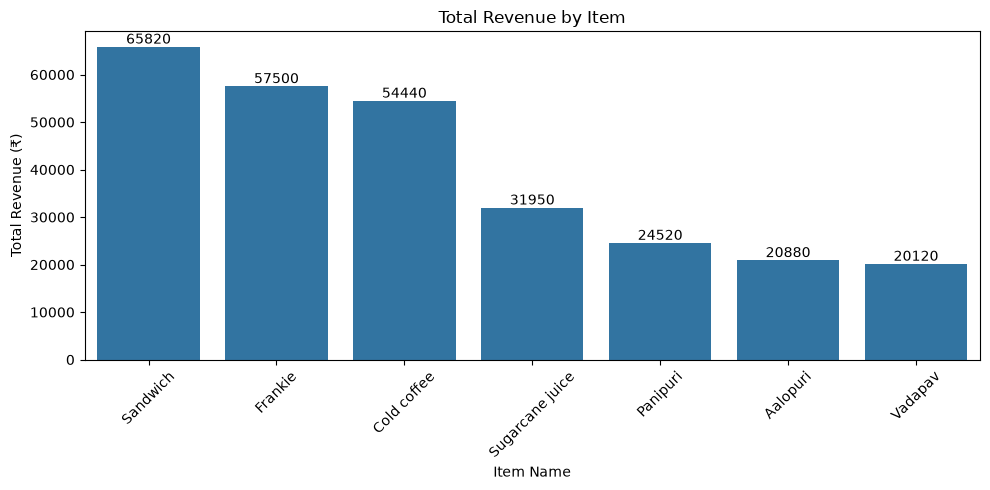

In [31]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=item_revenue.index,
    y=item_revenue.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Total Revenue by Item")
plt.xlabel("Item Name")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [32]:
top_3_revenue = item_revenue.head(3).sum()

total_revenue = df["transaction_amount"].sum()

top_3_percentage = (top_3_revenue / total_revenue) * 100

print("Top 3 Items Revenue:", top_3_revenue)

print("Total Revenue:", total_revenue)

print("Top 3 Revenue Share:", round(top_3_percentage, 2), "%")

Top 3 Items Revenue: 177760
Total Revenue: 275230
Top 3 Revenue Share: 64.59 %


In [33]:
time_analysis = df.groupby("time_of_sale").agg(
    total_revenue=("transaction_amount", "sum"),
    average_bill=("transaction_amount", "mean")
)

print(time_analysis.round(2))

              total_revenue  average_bill
time_of_sale                             
Afternoon             56345        274.85
Evening               52355        260.47
Midnight              50725        254.90
Morning               53730        282.79
Night                 62075        302.80


In [34]:
highest_revenue_time = time_analysis["total_revenue"].idxmax()

highest_average_bill_time = time_analysis["average_bill"].idxmax()

print("Highest Revenue Time:", highest_revenue_time)

print("Highest Average Bill Time:", highest_average_bill_time)

Highest Revenue Time: Night
Highest Average Bill Time: Night


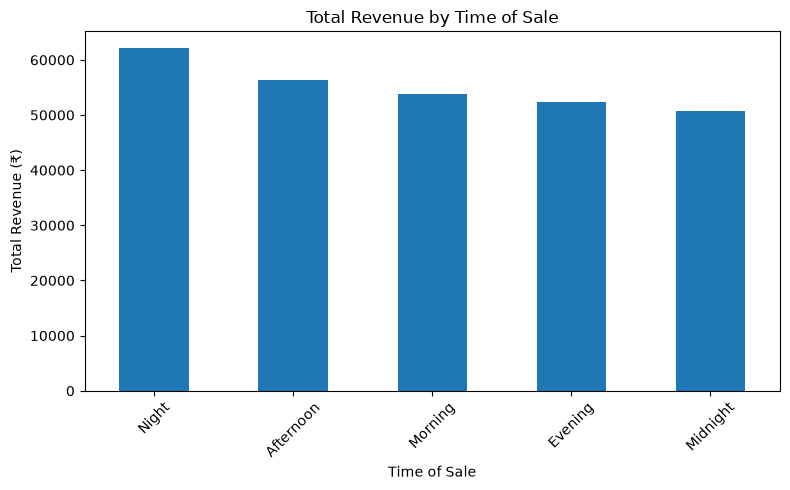

In [35]:
time_analysis["total_revenue"].sort_values(
    ascending=False
).plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Revenue by Time of Sale"
)

plt.xlabel("Time of Sale")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

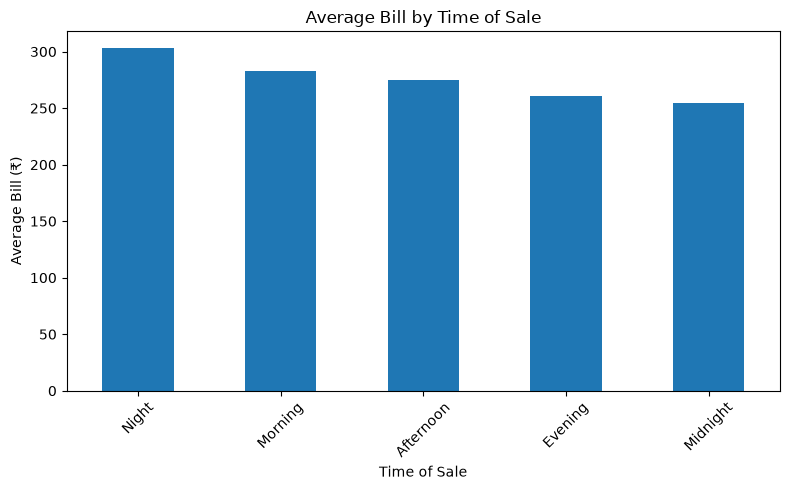

In [36]:
time_analysis["average_bill"].sort_values(
    ascending=False
).plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Bill by Time of Sale"
)

plt.xlabel("Time of Sale")
plt.ylabel("Average Bill (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
monthly_revenue = (
    df.groupby(df["date"].dt.to_period("M"))["transaction_amount"]
    .sum()
)

monthly_revenue.index = monthly_revenue.index.astype(str)

print(monthly_revenue)

date
2022-01    5785
2022-02    8010
2022-03    4720
2022-04    8550
2022-05    5800
2022-06    4080
2022-07    6700
2022-08    6695
2022-09    9435
2022-10    5100
2022-11    6970
2022-12    6420
2023-01    3965
2023-02    2825
2023-03    4595
2023-04    3450
2023-05    5015
2023-06    2490
2023-07    2030
2023-08    1680
2023-09    2530
2023-10    1955
2023-11    1535
2023-12    1380
Name: transaction_amount, dtype: int64


In [38]:
best_month = monthly_revenue.idxmax()

worst_month = monthly_revenue.idxmin()

print("Best Month:", best_month)
print("Best Month Revenue:", monthly_revenue.max())

print("Worst Month:", worst_month)
print("Worst Month Revenue:", monthly_revenue.min())

Best Month: 2022-09
Best Month Revenue: 9435
Worst Month: 2023-12
Worst Month Revenue: 1380


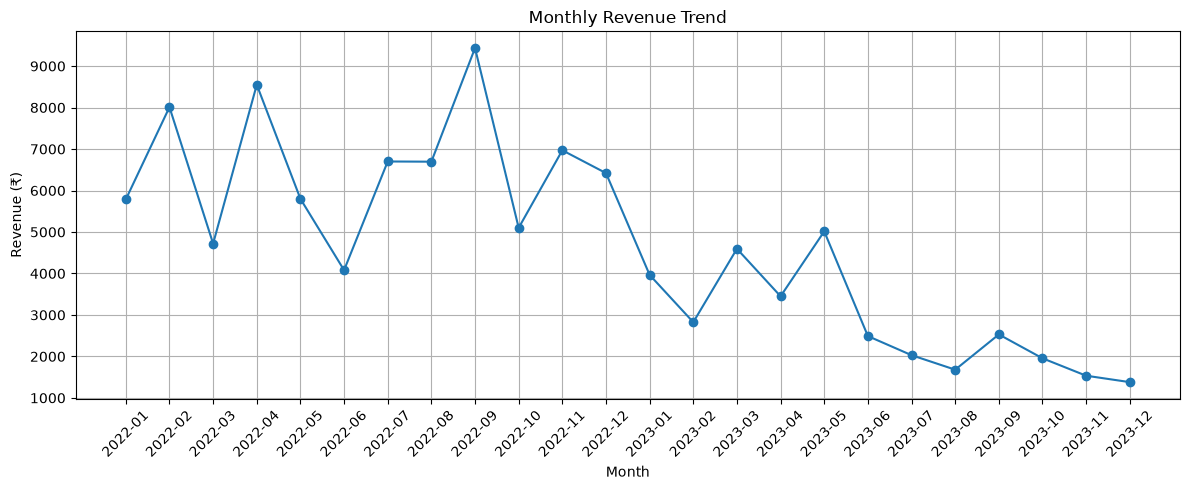

In [39]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
first_month = monthly_revenue.iloc[0]
last_month = monthly_revenue.iloc[-1]

if last_month > first_month:
    print("Revenue increased from the first month to the last month.")
elif last_month < first_month:
    print("Revenue decreased from the first month to the last month.")
else:
    print("Revenue was the same in the first and last months.")

Revenue decreased from the first month to the last month.


In [41]:
payment_counts = pd.crosstab(
    df["item_type"],
    df["transaction_type"]
)

print(payment_counts)

transaction_type  Cash  Online  Unknown
item_type                              
Beverages          148     126       40
Fastfood           328     291       67


In [42]:
payment_percentage = pd.crosstab(
    df["item_type"],
    df["transaction_type"],
    normalize="index"
) * 100

print(payment_percentage.round(2))

transaction_type   Cash  Online  Unknown
item_type                               
Beverages         47.13   40.13    12.74
Fastfood          47.81   42.42     9.77


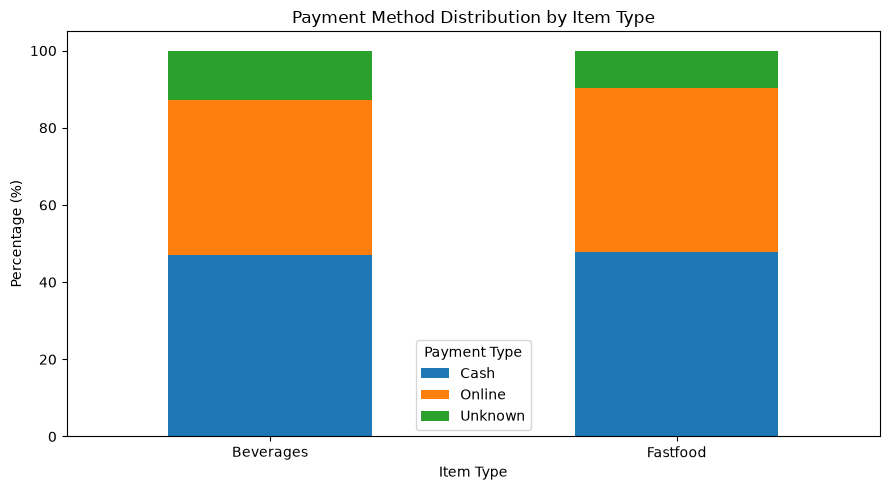

In [43]:
payment_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Payment Method Distribution by Item Type")
plt.xlabel("Item Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)

plt.legend(title="Payment Type")
plt.tight_layout()
plt.show()

In [44]:
if "Online" in payment_percentage.columns:
    online_payment = payment_percentage["Online"]

    print("Online Payment Percentage:")
    print(online_payment.round(2))

    print(
        "Higher Online Payment:",
        online_payment.idxmax()
    )
else:
    print("Online payment category was not found.")

Online Payment Percentage:
item_type
Beverages    40.13
Fastfood     42.42
Name: Online, dtype: float64
Higher Online Payment: Fastfood


In [45]:
daily_revenue = (
    df.groupby("date")
    .agg(
        daily_revenue=("transaction_amount", "sum"),
        is_weekend=("is_weekend", "first")
    )
)

print(daily_revenue.head())

            daily_revenue  is_weekend
date                                 
2022-01-04            420       False
2022-01-05            260       False
2022-01-06            120       False
2022-01-07           1235       False
2022-01-08            250        True


In [46]:
week_comparison = daily_revenue.groupby("is_weekend")[
    "daily_revenue"
].mean()

week_comparison.index = [
    "Weekend" if value else "Weekday"
    for value in week_comparison.index
]

print(week_comparison.round(2))

Weekday    835.71
Weekend    764.49
Name: daily_revenue, dtype: float64


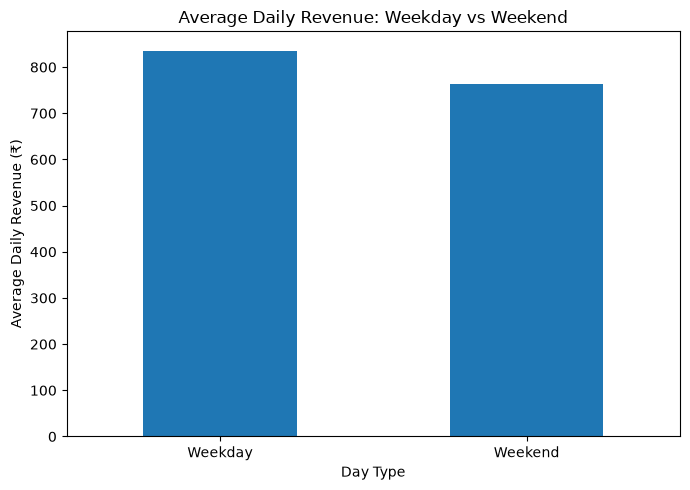

In [47]:
week_comparison.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Daily Revenue: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Revenue (₹)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [48]:
weekday_revenue = daily_revenue.loc[
    ~daily_revenue["is_weekend"],
    "daily_revenue"
].mean()

weekend_revenue = daily_revenue.loc[
    daily_revenue["is_weekend"],
    "daily_revenue"
].mean()

print("Average Weekday Revenue:", round(weekday_revenue, 2))
print("Average Weekend Revenue:", round(weekend_revenue, 2))

if weekend_revenue > weekday_revenue:
    print("Weekend average daily revenue is higher.")
elif weekend_revenue < weekday_revenue:
    print("Weekday average daily revenue is higher.")
else:
    print("Average daily revenue is equal.")

Average Weekday Revenue: 835.71
Average Weekend Revenue: 764.49
Weekday average daily revenue is higher.


In [49]:
staff_analysis = df.groupby("received_by").agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("transaction_amount", "sum"),
    average_bill=("transaction_amount", "mean")
)

print(staff_analysis.round(2))

             total_orders  total_revenue  average_bill
received_by                                           
Mr.                   512         143440        280.16
Mrs.                  488         131790        270.06


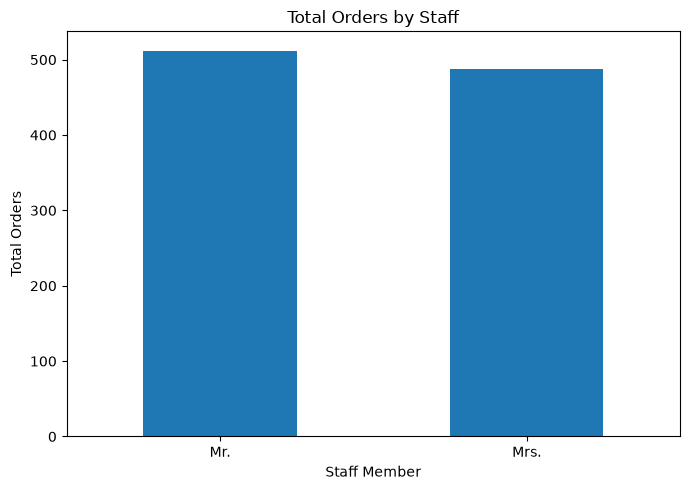

In [50]:
staff_analysis["total_orders"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Total Orders by Staff")
plt.xlabel("Staff Member")
plt.ylabel("Total Orders")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

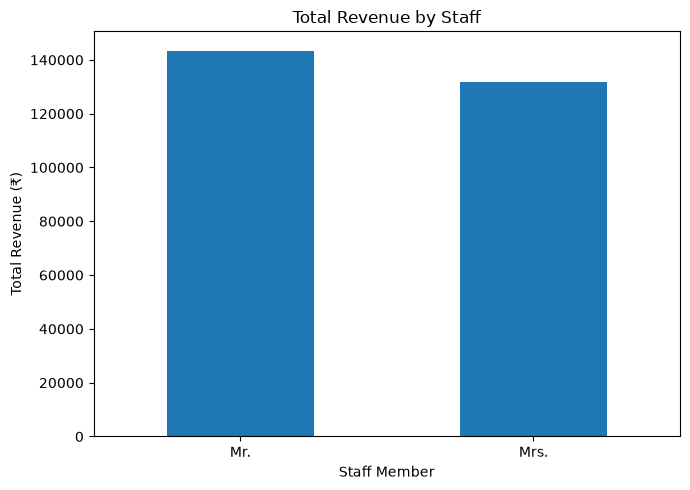

In [51]:
staff_analysis["total_revenue"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Total Revenue by Staff")
plt.xlabel("Staff Member")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

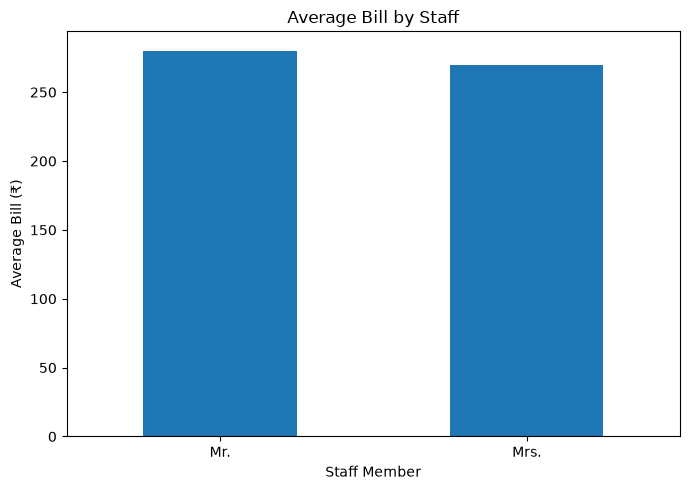

In [52]:
staff_analysis["average_bill"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Bill by Staff")
plt.xlabel("Staff Member")
plt.ylabel("Average Bill (₹)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [53]:
print(
    "Difference in Orders:",
    abs(
        staff_analysis["total_orders"].iloc[0]
        - staff_analysis["total_orders"].iloc[1]
    )
)

print(
    "Difference in Revenue:",
    round(
        abs(
            staff_analysis["total_revenue"].iloc[0]
            - staff_analysis["total_revenue"].iloc[1]
        ),
        2
    )
)

print(
    "Difference in Average Bill:",
    round(
        abs(
            staff_analysis["average_bill"].iloc[0]
            - staff_analysis["average_bill"].iloc[1]
        ),
        2
    )
)

Difference in Orders: 24
Difference in Revenue: 11650
Difference in Average Bill: 10.09


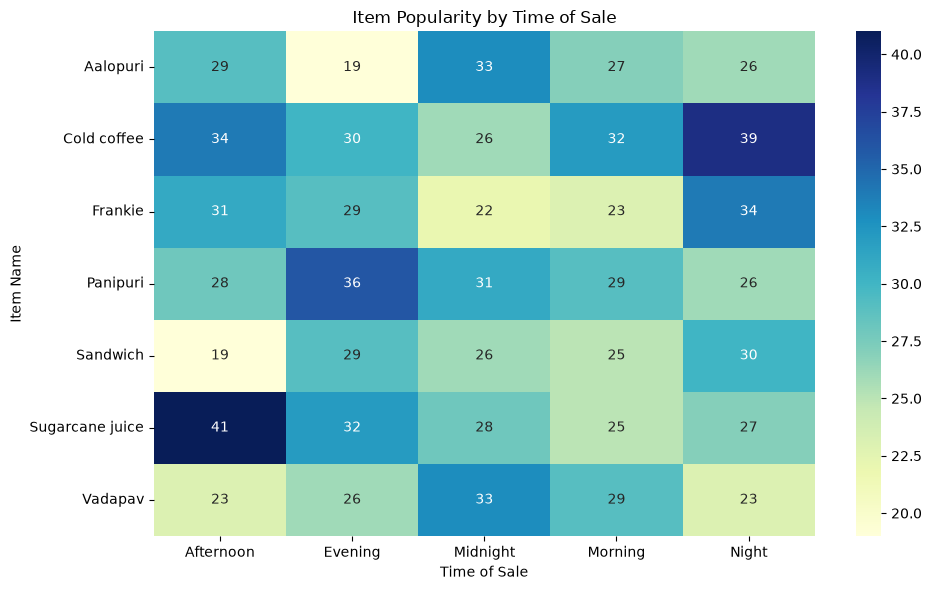

In [54]:


# Create a table of orders by item and time
order_heatmap = pd.crosstab(
    df["item_name"],
    df["time_of_sale"]
)

# Plot heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    order_heatmap,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Item Popularity by Time of Sale")
plt.xlabel("Time of Sale")
plt.ylabel("Item Name")
plt.tight_layout()
plt.show()

In [55]:
# Calculate revenue for each item
item_revenue = (
    df.groupby("item_name")["transaction_amount"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Calculate revenue percentage
total_revenue = item_revenue["transaction_amount"].sum()

item_revenue["revenue_percentage"] = (
    item_revenue["transaction_amount"] / total_revenue
) * 100

# Calculate cumulative percentage
item_revenue["cumulative_percentage"] = (
    item_revenue["revenue_percentage"].cumsum()
)

print(item_revenue)

# Find items contributing to approximately 80% revenue
print(
    item_revenue[
        item_revenue["cumulative_percentage"] <= 80
    ]
)

         item_name  transaction_amount  revenue_percentage  \
0         Sandwich               65820           23.914544   
1          Frankie               57500           20.891618   
2      Cold coffee               54440           19.779821   
3  Sugarcane juice               31950           11.608473   
4         Panipuri               24520            8.908913   
5         Aalopuri               20880            7.586382   
6          Vadapav               20120            7.310250   

   cumulative_percentage  
0              23.914544  
1              44.806162  
2              64.585983  
3              76.194456  
4              85.103368  
5              92.689750  
6             100.000000  
         item_name  transaction_amount  revenue_percentage  \
0         Sandwich               65820           23.914544   
1          Frankie               57500           20.891618   
2      Cold coffee               54440           19.779821   
3  Sugarcane juice               31950 

Correlation: 0.05036062705771535


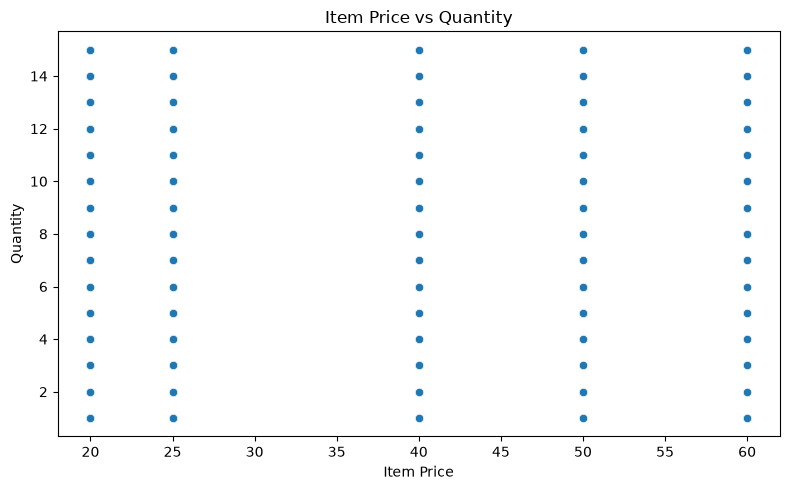

In [56]:
# Calculate correlation
correlation = df["item_price"].corr(df["quantity"])

print("Correlation:", correlation)

# Scatter plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="item_price",
    y="quantity"
)

plt.title("Item Price vs Quantity")
plt.xlabel("Item Price")
plt.ylabel("Quantity")
plt.tight_layout()
plt.show()

In [57]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Check negative prices
print("Negative Prices:")
print(df[df["item_price"] < 0])

# Check zero or negative quantities
print("Invalid Quantities:")
print(df[df["quantity"] <= 0])

# Check transaction amount calculation
df["calculated_amount"] = df["item_price"] * df["quantity"]

invalid_rows = df[
    ~df["transaction_amount"].eq(df["calculated_amount"])
]

print("Incorrect Transaction Amount Rows:")
print(invalid_rows)

Missing Values:
order_id                0
date                  597
item_name               0
item_type               0
item_price              0
quantity                0
transaction_amount      0
transaction_type        0
received_by             0
time_of_sale            0
calculated_amount       0
amount_matches          0
month                 597
weekday               597
is_weekend              0
dtype: int64
Duplicate Rows: 0
Negative Prices:
Empty DataFrame
Columns: [order_id, date, item_name, item_type, item_price, quantity, transaction_amount, transaction_type, received_by, time_of_sale, calculated_amount, amount_matches, month, weekday, is_weekend]
Index: []
Invalid Quantities:
Empty DataFrame
Columns: [order_id, date, item_name, item_type, item_price, quantity, transaction_amount, transaction_type, received_by, time_of_sale, calculated_amount, amount_matches, month, weekday, is_weekend]
Index: []
Incorrect Transaction Amount Rows:
Empty DataFrame
Columns: [order_id, date, i

In [58]:
df.to_csv("Balaji_Cleaned_Sales.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [59]:
import os

print(os.getcwd())

C:\Users\gaura\python all files


In [60]:
import os

print("Current Folder:", os.getcwd())
print("Files in Folder:", os.listdir())

Current Folder: C:\Users\gaura\python all files
Files in Folder: ['.ipynb_checkpoints', 'balaji fooods project.ipynb', 'Balaji_Cleaned_Sales.csv', 'Day 1.ipynb', 'day 2.ipynb', 'exception handling .ipynb', 'final Project.ipynb', 'funtions in python.ipynb', 'library.ipynb', 'List and tuple .ipynb', 'Mini projects .ipynb', 'OOPs.ipynb', 'pandas.ipynb', 'pandas1 (1).ipynb', 'pandas1.ipynb', 'practice.ipynb', 'project file.ipynb', 'question bank.ipynb', 'Set and dictionaries .ipynb', 'string funtion.ipynb', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled2.ipynb']


In [64]:
import os

folder = r"C:\Users\gaura\python all files"

for file in os.listdir(folder):
    if "Balaji" in file:
        print(file)

Balaji_Cleaned_Sales.csv


In [65]:
df.to_csv(
    r"C:\Users\gaura\python all files\Balaji_Cleaned_Sales.csv",
    index=False
)

print("CSV file saved successfully!")

CSV file saved successfully!


In [66]:
df.to_csv("Balaji_Cleaned_Sales.csv", index=False)

In [67]:
import os

folder = r"C:\Users\gaura\python all files"

for file in os.listdir(folder):
    if file.endswith(".csv"):
        print(file)

Balaji_Cleaned_Sales.csv
